In [1]:
print("Deep Learning NLP Text Classifier")
print("Project Started Successfully!")
print("Welcome to Python Programming")

Deep Learning NLP Text Classifier
Project Started Successfully!
Welcome to Python Programming


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)
print("All Libraries Imported Successfully!")

TensorFlow Version: 2.21.0
NumPy Version: 2.4.6
All Libraries Imported Successfully!


In [3]:
from tensorflow.keras.datasets import imdb

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=10000)

print("Dataset Loaded Successfully!")
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("First Review:", X_train[0])
print("First Label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Dataset Loaded Successfully!
Training Samples: 25000
Testing Samples: 25000
First Review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 

In [4]:
word_index = imdb.get_word_index()

reverse_word_index = {
    value: key for key, value in word_index.items()
}

def decode_review(encoded_review):
    return " ".join(
        reverse_word_index.get(i - 3, "?")
        for i in encoded_review
        if i >= 3
    )

print("Sample Movie Review:")
print(decode_review(X_train[0]))

print("\nSentiment:", "Positive" if y_train[0] == 1 else "Negative")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Sample Movie Review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and

In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

X_train_padded = pad_sequences(X_train, maxlen=200)
X_test_padded = pad_sequences(X_test, maxlen=200)

print("Data Preparation Completed!")
print("Training Data Shape:", X_train_padded.shape)
print("Testing Data Shape:", X_test_padded.shape)

Data Preparation Completed!
Training Data Shape: (25000, 200)
Testing Data Shape: (25000, 200)


In [6]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(10000, 64, input_length=200),
    LSTM(64),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    X_train_padded,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 56s 178ms/step - accuracy: 0.9686 - loss: 0.0891 - val_accuracy: 0.8666 - val_loss: 0.5549
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 53s 169ms/step - accuracy: 0.9722 - loss: 0.0770 - val_accuracy: 0.8684 - val_loss: 0.4793
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 81s 166ms/step - accuracy: 0.9754 - loss: 0.0718 - val_accuracy: 0.8656 - val_loss: 0.5494
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 166ms/step - accuracy: 0.9817 - loss: 0.0533 - val_accuracy: 0.8598 - val_loss: 0.5610
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 167ms/step - accuracy: 0.9862 - loss: 0.0423 - val_accuracy: 0.8566 - val_loss: 0.6082


In [9]:
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 25s 32ms/step - accuracy: 0.8476 - loss: 0.6473
Test Loss: 0.647331714630127
Test Accuracy: 84.76399779319763 %


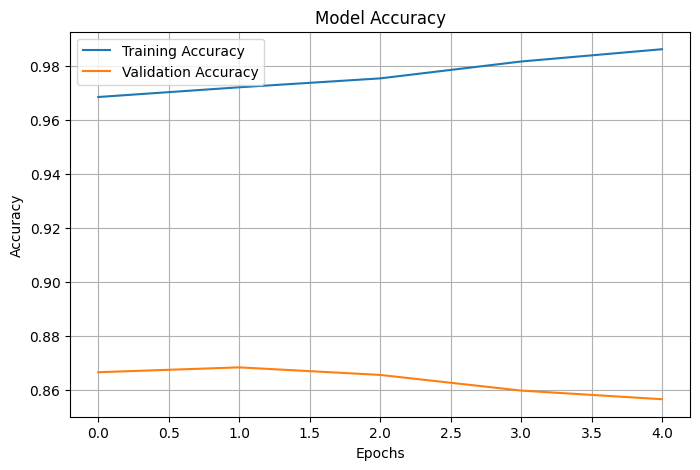

In [10]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

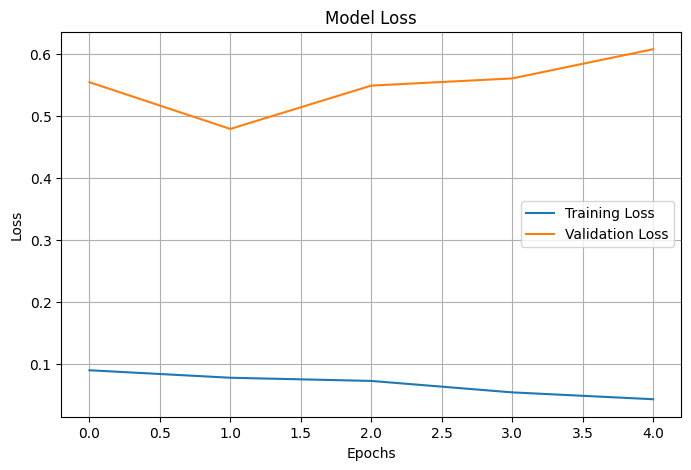

In [11]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

In [12]:
def predict_sentiment(review):
    words = review.lower().split()

    encoded = [word_index.get(word, 2) for word in words]

    padded = pad_sequences([encoded], maxlen=200)

    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Sentiment: Positive")
    else:
        print("Sentiment: Negative")

    print("Confidence:", round(float(max(prediction, 1-prediction))*100, 2), "%")


predict_sentiment("This movie is amazing and wonderful")

Sentiment: Positive
Confidence: 94.8 %


In [13]:
predict_sentiment("This movie is boring and terrible")

Sentiment: Positive
Confidence: 81.58 %


In [14]:
def predict_sentiment(review):
    words = tf.keras.preprocessing.text.text_to_word_sequence(review)

    encoded = [
        word_index.get(word, 2) + 3
        if word_index.get(word, 2) != 2 and word_index.get(word, 2) + 3 < 10000
        else 2
        for word in words
    ]

    padded = pad_sequences([encoded], maxlen=200)

    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        print("Sentiment: Positive")
    else:
        print("Sentiment: Negative")

    print("Confidence:", round(float(max(prediction, 1-prediction))*100, 2), "%")

In [15]:
predict_sentiment("This movie is amazing and wonderful")

predict_sentiment("This movie is boring and terrible")

Sentiment: Positive
Confidence: 98.2 %
Sentiment: Negative
Confidence: 99.92 %


In [16]:
model.save("sentiment_model.keras")

print("Model Saved Successfully!")

Model Saved Successfully!
